# CA2 - Section 1: Data Generation

This notebook implements Section 1 requirements:
1. Generate 20 random 4-character strings (lowercase letters + digits).
2. Create and save 20 images with labels.
3. Add salt-and-pepper noise and compare with original images.
4. Denoise using course filters and explain filter choice.

In [1]:
import os
import random
import string
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image, ImageDraw, ImageFont
from scipy.ndimage import convolve, median_filter, gaussian_filter, label as cc_label

# Reproducibility
random.seed(42)
np.random.seed(42)

### راهنمای صورت پروژه — فونت و تمایز حروف / ارقام

**فونت (طبق دستور):** برای این کار از کد زیر استفاده کنید:

`font = ImageFont.truetype("arial.ttf", 40)`

اگر فونت متفاوتی داشتید ولی به نتیجه رسیدید، نیازی به تغییر اجباری نیست.

**چالش تمایز:** تشخیص تفاوت بعضی حروف و اعداد (مثلاً شبیه بودن `l` به `1` یا `o` به `0`) از چالش‌های این پروژه است.

**ایده‌های راهنما (برای گزارش / بهبود تشخیص):**
- برای اشتباه بین `l` و `1`: می‌توان به **لبه‌ها** توجه کرد و آن‌ها را شمرد؛ در فونت Arial معمولاً برای «1» تعداد/چیدمان لبه‌ها با حرف «l» فرق دارد.
- برای `o` و `0`: می‌توان از **نسبت ابعاد** (aspect ratio نسبت به bounding box)، یا نسبت مساحت پیش‌زمینه به کل، کمک گرفت.
- در صورت پروژه به **resize کردن Mapset** اشاره شده؛ همسان‌سازی مقیاس با تصاویر قطعه‌شده می‌تواند در تمایز این جفت‌ها مؤثر باشد.

**در این نوت‌بوک:** برای کیفیت بهتر خروجی، متن ابتدا روی بوم بزرگ‌تر رسم می‌شود سپس با `LANCZOS` به اندازه نهایی کوچک می‌شود؛ **اندازه فونت طبق دستور 40** باقی مانده است.

In [2]:
# Paths
base_dir = Path("ca2_section1_data")
clean_dir = base_dir / "clean_images"
noisy_dir = base_dir / "noisy_images"
filtered_dir = base_dir / "filtered_images"

for d in [base_dir, clean_dir, noisy_dir, filtered_dir]:
    d.mkdir(parents=True, exist_ok=True)

alphabet = string.ascii_lowercase + string.digits
num_images = 20
text_len = 4

# Better image quality settings
OUTPUT_SIZE = (512, 512)
RENDER_SCALE = 4
RENDER_SIZE = (OUTPUT_SIZE[0] * RENDER_SCALE, OUTPUT_SIZE[1] * RENDER_SCALE)
MARGIN = int(RENDER_SIZE[0] * 0.12)
STROKE_WIDTH = max(2, RENDER_SIZE[0] // 360)

FONT_CANDIDATES = [
    # r"C:\Windows\Fonts\arialbd.ttf",
    r"C:\Windows\Fonts\arial.ttf",
#     "/System/Library/Fonts/Supplemental/Arial Bold.ttf",
#     "/Library/Fonts/Arial.ttf",
#     "/usr/share/fonts/truetype/dejavu/DejaVuSans-Bold.ttf",
#     "/usr/share/fonts/truetype/liberation2/LiberationSans-Bold.ttf",
]

# Find a good font automatically
def find_font_path():
    # 1. Try common font names directly
    direct_names = [
        # "DejaVuSans-Bold.ttf",
        # "DejaVuSans.ttf",
        # "Arial.ttf",
        "arial.ttf",
    ]

    for name in direct_names:
        try:
            ImageFont.truetype(name, 40)
            return name
        except:
            pass

    # 2. Search common folders
    search_dirs = [
        "/usr/share/fonts",
        "/usr/local/share/fonts",
        "/opt/conda/lib",
        "/usr/local/lib",
    ]

    preferred = [
        # "DejaVuSans-Bold.ttf",
        # "DejaVuSans.ttf",
        # "LiberationSans-Bold.ttf",
        # "Arial.ttf",
        "arial.ttf",
    ]

    for folder in search_dirs:
        folder = Path(folder)
        if folder.exists():
            for font_name in preferred:
                matches = list(folder.rglob(font_name))
                if matches:
                    return str(matches[0])

    # 3. Last fallback
    print("Warning: No TrueType font found. Using default font.")
    return None


FONT_PATH = find_font_path()
print("Font used:", FONT_PATH)


_resample = getattr(Image, "Resampling", Image).LANCZOS

def generate_text(n=4):
    return "".join(random.choices(alphabet, k=n))

def pick_font_size(label_text, canvas_size, font_path):
    tmp_draw = ImageDraw.Draw(Image.new("L", canvas_size, 0))
    lo, hi = 10, min(canvas_size[0], canvas_size[1])
    best = None

    while lo <= hi:
        mid = (lo + hi) // 2
        fnt = ImageFont.truetype(font_path, mid) if font_path else ImageFont.load_default()
        bbox = tmp_draw.textbbox((0, 0), label_text, font=fnt, stroke_width=STROKE_WIDTH)

        text_w = bbox[2] - bbox[0]
        text_h = bbox[3] - bbox[1]

        if text_w <= canvas_size[0] - MARGIN and text_h <= canvas_size[1] - MARGIN:
            best = (fnt, mid)
            lo = mid + 1
        else:
            hi = mid - 1

    if best is None:
        return ImageFont.truetype(font_path, 10) if font_path else ImageFont.load_default(), 10

    return best

records = []

CHAR_BOX_PADDING_X = 0.28   # bigger = more horizontal space
CHAR_BOX_PADDING_Y = 0.25   # bigger = smaller characters

def get_font_for_char(ch, box_w, box_h):
    max_w = int(box_w * (1 - CHAR_BOX_PADDING_X))
    max_h = int(box_h * (1 - CHAR_BOX_PADDING_Y))

    lo, hi = 10, box_h
    best_font = None

    temp_img = Image.new("L", (box_w, box_h), 0)
    temp_draw = ImageDraw.Draw(temp_img)

    while lo <= hi:
        mid = (lo + hi) // 2

        if FONT_PATH:
            font = ImageFont.truetype(FONT_PATH, mid)
        else:
            font = ImageFont.load_default()

        bbox = temp_draw.textbbox((0, 0), ch, font=font, stroke_width=STROKE_WIDTH)
        char_w = bbox[2] - bbox[0]
        char_h = bbox[3] - bbox[1]

        if char_w <= max_w and char_h <= max_h:
            best_font = font
            lo = mid + 1
        else:
            hi = mid - 1

    return best_font if best_font else ImageFont.load_default()


for idx in range(num_images):
    label = generate_text(text_len)

    img_hi = Image.new("L", RENDER_SIZE, color=0)
    draw = ImageDraw.Draw(img_hi)

    box_w = RENDER_SIZE[0] // text_len
    box_h = RENDER_SIZE[1]

    for i, ch in enumerate(label):
        font = get_font_for_char(ch, box_w, box_h)

        bbox = draw.textbbox((0, 0), ch, font=font, stroke_width=STROKE_WIDTH)
        char_w = bbox[2] - bbox[0]
        char_h = bbox[3] - bbox[1]

        box_x = i * box_w

        x = box_x + (box_w - char_w) // 2 - bbox[0]
        y = (box_h - char_h) // 2 - bbox[1]

        draw.text(
            (x, y),
            ch,
            fill=255,
            font=font,
            stroke_width=STROKE_WIDTH,
            stroke_fill=255,
        )

    img = img_hi.resize(OUTPUT_SIZE, _resample)

    filename = f"img_{idx:02d}.png"
    img.save(clean_dir / filename, optimize=True)

    records.append({
        "filename": filename,
        "label": label
    })

labels_df = pd.DataFrame(records)
labels_path = base_dir / "labels.csv"
labels_df.to_csv(labels_path, index=False)

print(f"Generated {len(labels_df)} clean images in: {clean_dir}")
print(f"Saved labels to: {labels_path}")
print(f"Font used: {FONT_PATH}")
print(f"Output image size: {OUTPUT_SIZE}")

labels_df.head()

Font used: /usr/local/lib/python3.12/dist-packages/geemap/data/fonts/arial.ttf
Generated 20 clean images in: ca2_section1_data/clean_images
Saved labels to: ca2_section1_data/labels.csv
Font used: /usr/local/lib/python3.12/dist-packages/geemap/data/fonts/arial.ttf
Output image size: (512, 512)


,filename,label
0,img_00.png,xaji
1,img_01.png,0y6d
2,img_02.png,pbhs
3,img_03.png,ahxt
4,img_04.png,hv3a


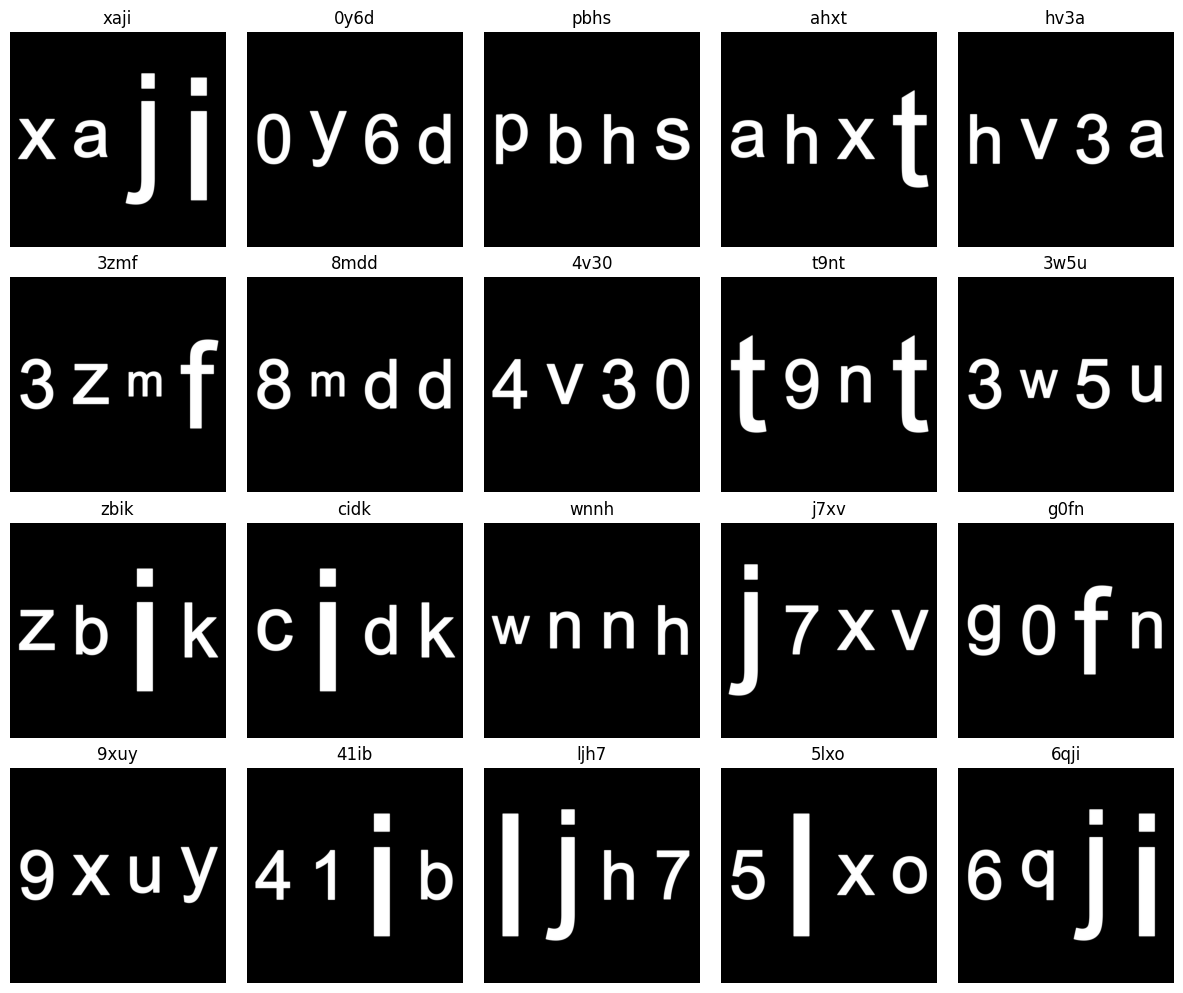

In [3]:
# Quick visualization of generated clean images
fig, axes = plt.subplots(4, 5, figsize=(12, 10))
axes = axes.ravel()

for i, row in labels_df.iterrows():
    img = Image.open(clean_dir / row["filename"])
    axes[i].imshow(img, cmap="gray", vmin=0, vmax=255)
    axes[i].set_title(row["label"])
    axes[i].axis("off")

plt.tight_layout()
plt.show()

In [4]:
def add_salt_pepper_noise(img_array, amount=0.03, salt_vs_pepper=0.5):
    noisy = img_array.copy()
    h, w = noisy.shape
    total_pixels = h * w
    num_noisy = int(amount * total_pixels)

    # Salt (white)
    num_salt = int(num_noisy * salt_vs_pepper)
    ys = np.random.randint(0, h, num_salt)
    xs = np.random.randint(0, w, num_salt)
    noisy[ys, xs] = 255

    # Pepper (black)
    num_pepper = num_noisy - num_salt
    ys = np.random.randint(0, h, num_pepper)
    xs = np.random.randint(0, w, num_pepper)
    noisy[ys, xs] = 0

    return noisy

for row in records:
    clean_img = np.array(Image.open(clean_dir / row["filename"]).convert("L"))
    noisy_img = add_salt_pepper_noise(clean_img, amount=0.03, salt_vs_pepper=0.5)
    Image.fromarray(noisy_img.astype(np.uint8)).save(noisy_dir / row["filename"])

print(f"Saved noisy images to: {noisy_dir}")

Saved noisy images to: ca2_section1_data/noisy_images


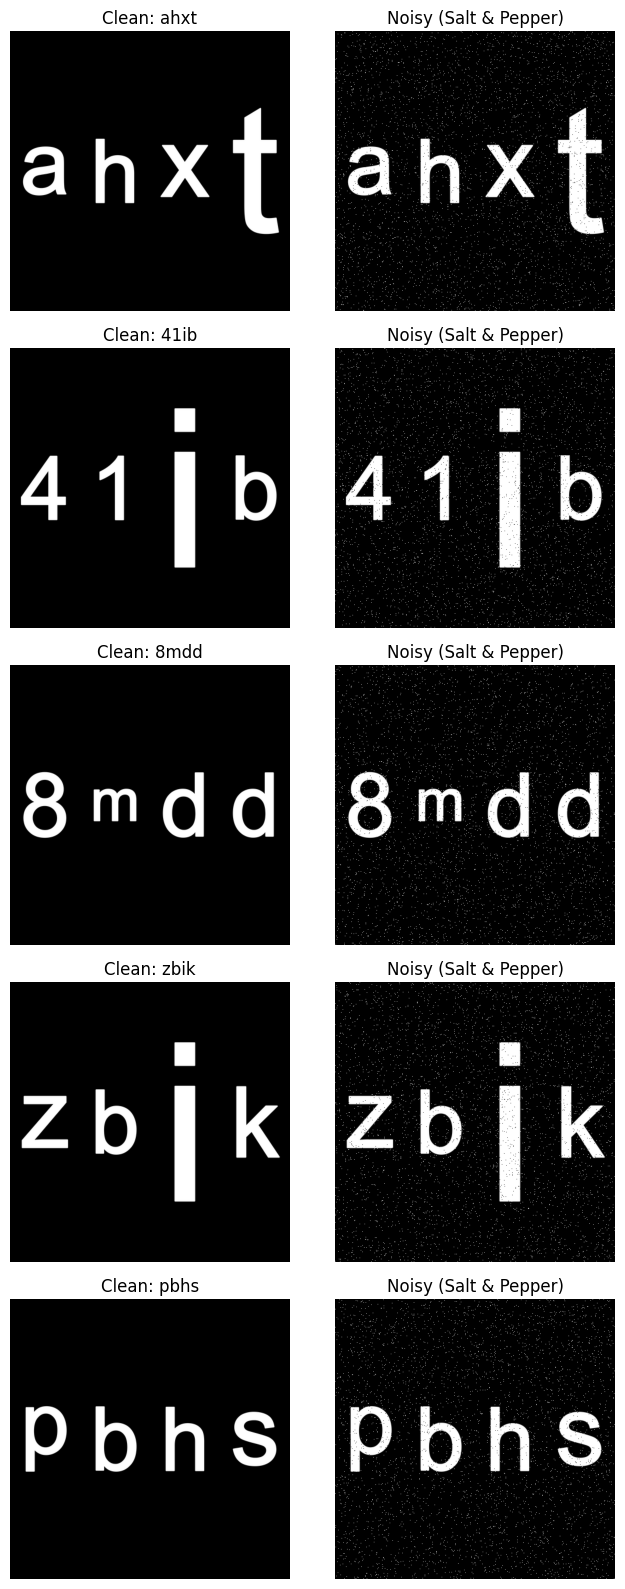

In [5]:
# Compare clean vs noisy for 5 sample images
sample_rows = labels_df.sample(5, random_state=1).reset_index(drop=True)

fig, axes = plt.subplots(5, 2, figsize=(7, 16))
for i, row in sample_rows.iterrows():
    clean_img = np.array(Image.open(clean_dir / row["filename"]).convert("L"))
    noisy_img = np.array(Image.open(noisy_dir / row["filename"]).convert("L"))

    axes[i, 0].imshow(clean_img, cmap="gray", vmin=0, vmax=255)
    axes[i, 0].set_title(f"Clean: {row['label']}")
    axes[i, 0].axis("off")

    axes[i, 1].imshow(noisy_img, cmap="gray", vmin=0, vmax=255)
    axes[i, 1].set_title("Noisy (Salt & Pepper)")
    axes[i, 1].axis("off")

plt.tight_layout()
plt.show()

In [6]:
# Course-style filters: mean (linear kernel) and median filter
mean_kernel = np.array([
    [1, 1, 1],
    [1, 1, 1],
    [1, 1, 1]
], dtype=np.float32) / 9.0

for row in records:
    noisy_img = np.array(Image.open(noisy_dir / row["filename"]).convert("L"), dtype=np.float32)

    mean_filtered = convolve(noisy_img, mean_kernel, mode="reflect")
    median_filtered = median_filter(noisy_img, size=3)

    # Save median result as final denoised output (best for impulsive S&P noise)
    Image.fromarray(np.clip(median_filtered, 0, 255).astype(np.uint8)).save(filtered_dir / row["filename"])

print(f"Saved denoised images (median) to: {filtered_dir}")

Saved denoised images (median) to: ca2_section1_data/filtered_images


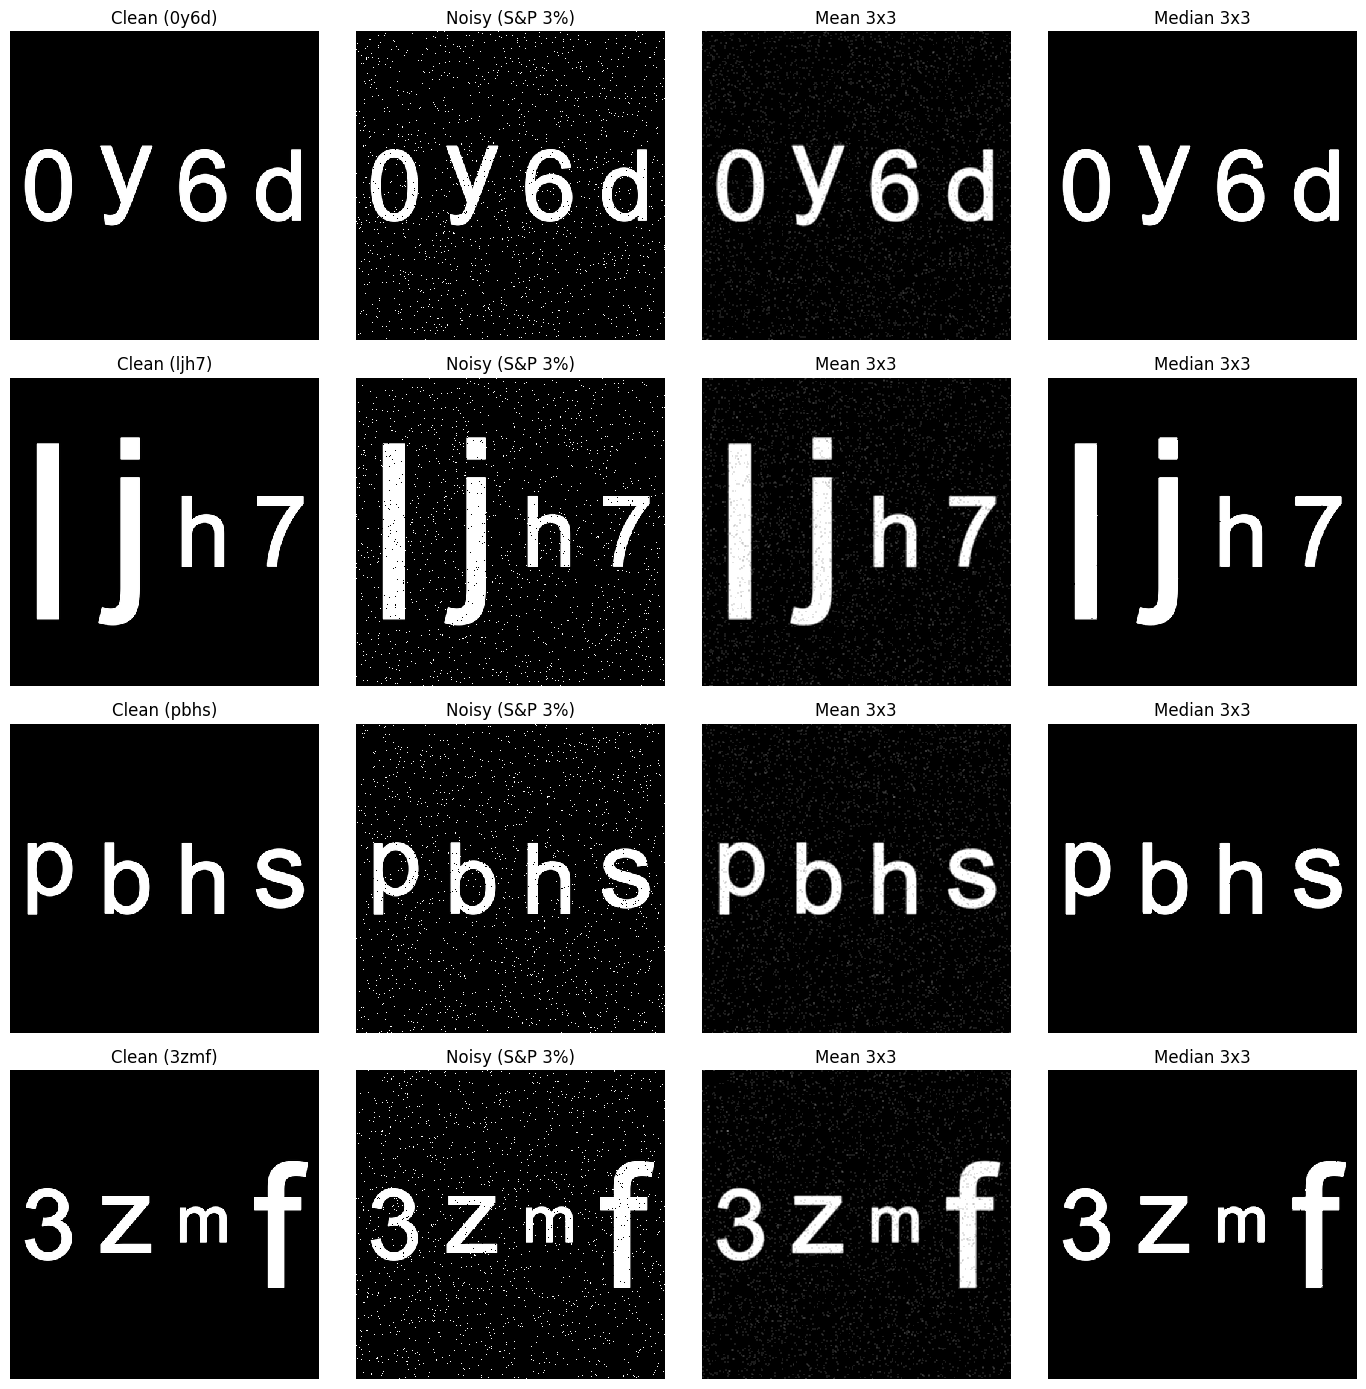

In [7]:
# Visual comparison: clean vs noisy vs mean-filtered vs median-filtered
sample_rows = labels_df.sample(4, random_state=7).reset_index(drop=True)

fig, axes = plt.subplots(4, 4, figsize=(14, 14))
for i, row in sample_rows.iterrows():
    clean_img = np.array(Image.open(clean_dir / row["filename"]).convert("L"), dtype=np.float32)
    noisy_img = np.array(Image.open(noisy_dir / row["filename"]).convert("L"), dtype=np.float32)

    mean_filtered = convolve(noisy_img, mean_kernel, mode="reflect")
    median_filtered = median_filter(noisy_img, size=3)

    axes[i, 0].imshow(clean_img, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
    axes[i, 0].set_title(f"Clean ({row['label']})")
    axes[i, 0].axis("off")

    axes[i, 1].imshow(noisy_img, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
    axes[i, 1].set_title("Noisy (S&P 3%)")
    axes[i, 1].axis("off")

    axes[i, 2].imshow(mean_filtered, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
    axes[i, 2].set_title("Mean 3x3")
    axes[i, 2].axis("off")

    axes[i, 3].imshow(median_filtered, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
    axes[i, 3].set_title("Median 3x3")
    axes[i, 3].axis("off")

plt.tight_layout()
plt.show()

## Why median filter is selected

Salt-and-pepper noise is **impulse noise** (isolated extreme black/white pixels).

- **Mean filter (3x3 kernel)** averages neighbors and can reduce noise, but it also blurs character edges.
- **Median filter (3x3)** replaces each pixel with the neighborhood median, which removes isolated impulses more effectively while preserving text boundaries.

So for this section, the **median filter** is the preferred choice for final denoising.

# Section 2 - Preprocessing

In this section we implement:
1. Blur-based noise reduction with a different kernel than Section 1.
2. Deblurring/Sharpening to recover details.
3. Binarization + removing small connected components using a threshold.

In [8]:
# Use one sample image from Section 1 outputs
sample_row = labels_df.sample(1, random_state=11).iloc[0]
sample_name = sample_row["filename"]
sample_label = sample_row["label"]

clean_img = np.array(Image.open(clean_dir / sample_name).convert("L"), dtype=np.float32)
noisy_img = np.array(Image.open(noisy_dir / sample_name).convert("L"), dtype=np.float32)

print(f"Sample file: {sample_name} | Label: {sample_label}")

Sample file: img_03.png | Label: ahxt


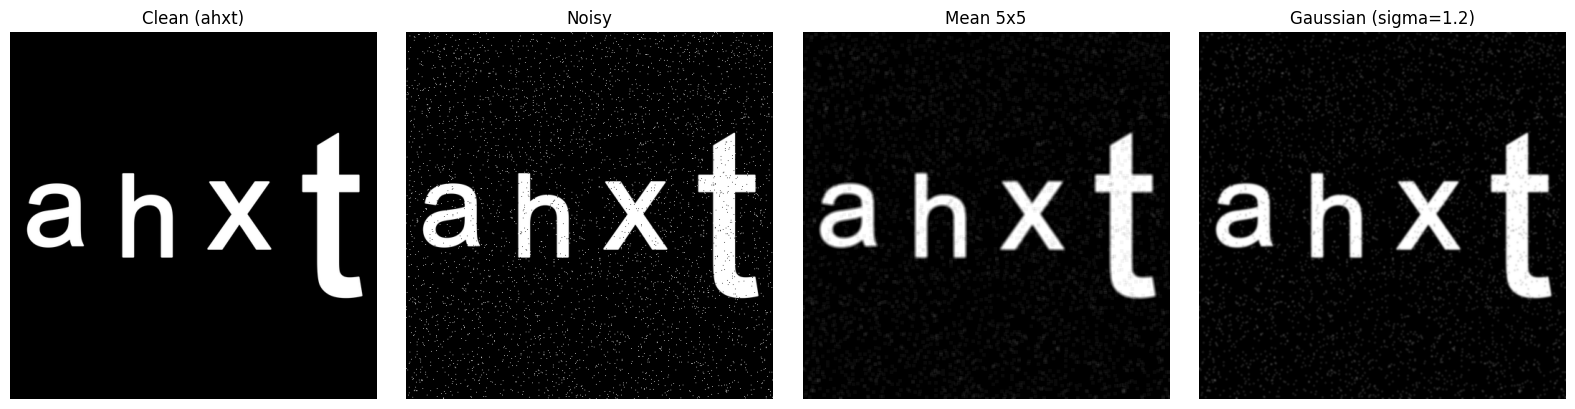

In [9]:
# 2.1 Blur-based denoising with different kernels (NOT 3x3)
mean5_kernel = np.ones((5, 5), dtype=np.float32) / 25.0
mean5_img = convolve(noisy_img, mean5_kernel, mode="reflect")

gauss_img = gaussian_filter(noisy_img, sigma=1.2)

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
axes[0].imshow(clean_img, cmap="gray", vmin=0, vmax=255)
axes[0].set_title(f"Clean ({sample_label})")
axes[0].axis("off")

axes[1].imshow(noisy_img, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("Noisy")
axes[1].axis("off")

axes[2].imshow(mean5_img, cmap="gray", vmin=0, vmax=255)
axes[2].set_title("Mean 5x5")
axes[2].axis("off")

axes[3].imshow(gauss_img, cmap="gray", vmin=0, vmax=255)
axes[3].set_title("Gaussian (sigma=1.2)")
axes[3].axis("off")

plt.tight_layout()
plt.show()

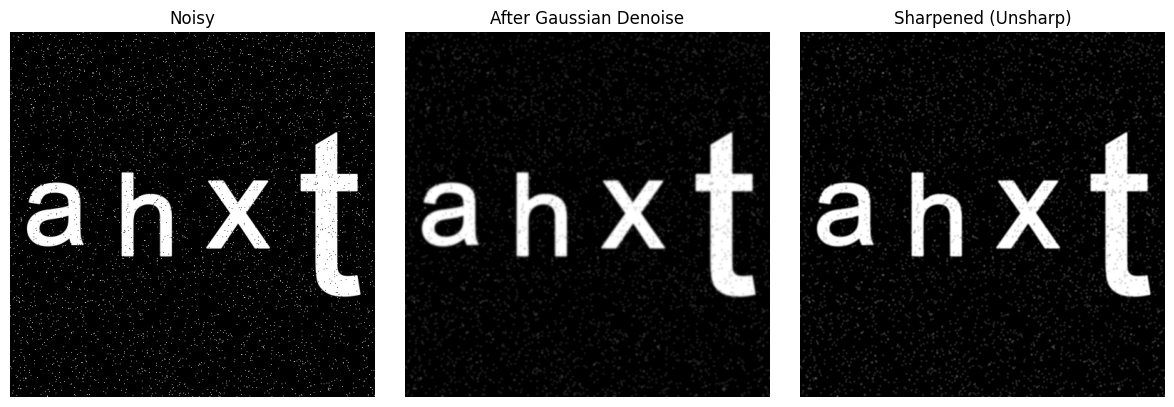

In [10]:
# 2.2 Deblurring / Sharpening (Unsharp Mask)
# We choose sharpening because blur filters reduce noise but also soften edges.

base_for_sharpen = gauss_img  # denoised image from previous step
blurred_for_mask = gaussian_filter(base_for_sharpen, sigma=1.0)
amount = 1.6
sharpened = np.clip(base_for_sharpen + amount * (base_for_sharpen - blurred_for_mask), 0, 255)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(noisy_img, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Noisy")
axes[0].axis("off")

axes[1].imshow(base_for_sharpen, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("After Gaussian Denoise")
axes[1].axis("off")

axes[2].imshow(sharpened, cmap="gray", vmin=0, vmax=255)
axes[2].set_title("Sharpened (Unsharp)")
axes[2].axis("off")

plt.tight_layout()
plt.show()

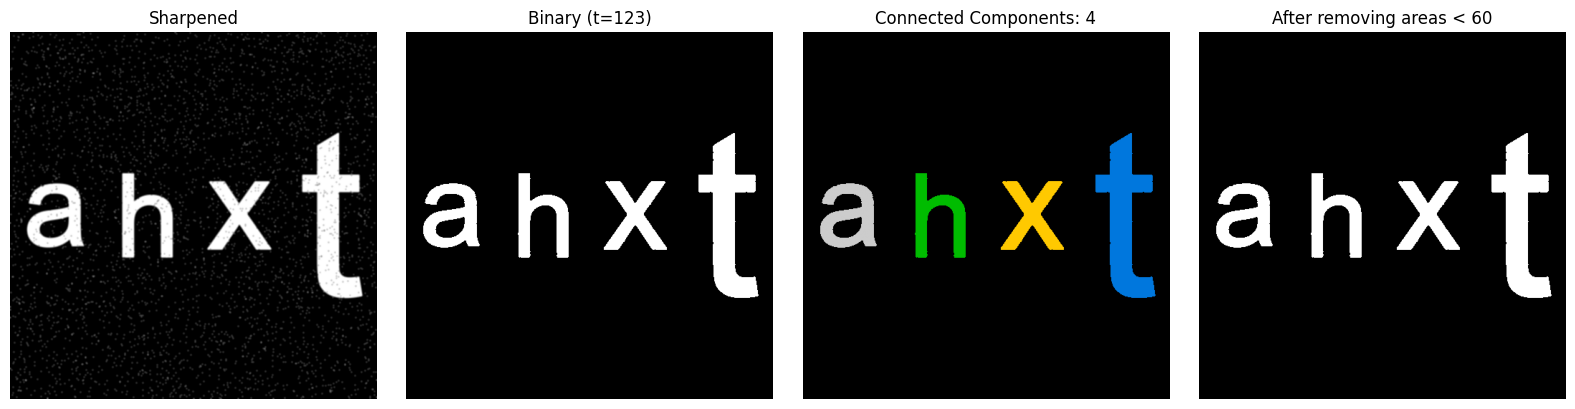

In [11]:
# 2.3 Binarization + remove small connected components

def otsu_threshold(gray_img):
    hist, _ = np.histogram(gray_img.ravel(), bins=256, range=(0, 256))
    hist = hist.astype(np.float64)
    p = hist / hist.sum()

    omega = np.cumsum(p)
    mu = np.cumsum(p * np.arange(256))
    mu_t = mu[-1]

    sigma_b2 = (mu_t * omega - mu) ** 2 / (omega * (1 - omega) + 1e-12)
    return int(np.argmax(sigma_b2))

t = otsu_threshold(sharpened)
# Light text on dark background -> foreground = pixels brighter than threshold
binary = sharpened > t

labeled, n_comp = cc_label(binary)
areas = np.bincount(labeled.ravel())
min_size = 60

clean_binary = binary.copy()
for comp_id in range(1, len(areas)):
    if areas[comp_id] < min_size:
        clean_binary[labeled == comp_id] = False

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
axes[0].imshow(sharpened, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Sharpened")
axes[0].axis("off")

axes[1].imshow(binary, cmap="gray")
axes[1].set_title(f"Binary (t={t})")
axes[1].axis("off")

axes[2].imshow(labeled, cmap="nipy_spectral")
axes[2].set_title(f"Connected Components: {n_comp}")
axes[2].axis("off")

axes[3].imshow(clean_binary, cmap="gray")
axes[3].set_title(f"After removing areas < {min_size}")
axes[3].axis("off")

plt.tight_layout()
plt.show()

## Section 2 Notes (for report)

- Blur filters (like mean and Gaussian) reduce random noise by averaging neighborhoods, but they also blur edges.
- We used a **different kernel** than Section 1 (`5x5` instead of `3x3`) to increase smoothing.
- For blur recovery, we selected **Sharpening (Unsharp Mask)** because it is simple and effective for restoring character edges after denoising.
- In the thresholding step, **threshold `t`** is the gray-level cut-point separating foreground from background.
- `t` is **not always constant**; it depends on image intensity distribution and can change per image (Otsu estimates it automatically).
- `min_size` is another threshold: minimum connected-component area to keep; smaller components are considered noise and removed.

# Section 3 - Segmentation

Goals:
1. Convert outputs to binary and segment characters individually.
2. Report number of extracted characters per image.
3. Resize each segmented character to `64x64` for the next Mapset stage.

In [12]:
# Section 3 folders
seg_base_dir = base_dir / "section3_segmentation"
binary_dir = seg_base_dir / "binary_images"
char_raw_dir = seg_base_dir / "char_raw"
char_64_dir = seg_base_dir / "char_64x64"

for d in [seg_base_dir, binary_dir, char_raw_dir, char_64_dir]:
    d.mkdir(parents=True, exist_ok=True)

print(f"Segmentation outputs will be saved in: {seg_base_dir}")

Segmentation outputs will be saved in: ca2_section1_data/section3_segmentation


In [13]:
def remove_small_components(binary_img, min_size=20):
    comp_map, _ = cc_label(binary_img)
    areas = np.bincount(comp_map.ravel())
    cleaned = binary_img.copy()
    for comp_id in range(1, len(areas)):
        if areas[comp_id] < min_size:
            cleaned[comp_map == comp_id] = False
    return cleaned


def segment_characters(binary_img, min_size=20):
    cleaned = remove_small_components(binary_img, min_size=min_size)
    comp_map, n_comp = cc_label(cleaned)

    boxes = []
    for comp_id in range(1, n_comp + 1):
        ys, xs = np.where(comp_map == comp_id)
        if ys.size == 0:
            continue
        y0, y1 = ys.min(), ys.max() + 1
        x0, x1 = xs.min(), xs.max() + 1
        boxes.append((x0, y0, x1, y1))

    # Left-to-right order to match text reading order
    boxes.sort(key=lambda b: b[0])

    char_patches = []
    for (x0, y0, x1, y1) in boxes:
        patch = cleaned[y0:y1, x0:x1]
        char_patches.append((patch, (x0, y0, x1, y1)))

    return cleaned, char_patches

In [14]:
# Run segmentation for all images
seg_records = []

for row in records:
    fname = row["filename"]
    img_id = Path(fname).stem

    # Start from denoised outputs of Section 1
    gray = np.array(Image.open(filtered_dir / fname).convert("L"), dtype=np.float32)

    # Otsu threshold (light text on dark bg => foreground is gray > t)
    t_img = otsu_threshold(gray)
    binary = gray > t_img

    # Clean and segment
    clean_bin, chars = segment_characters(binary, min_size=20)

    # Save binary image (0/255)
    Image.fromarray((clean_bin * 255).astype(np.uint8)).save(binary_dir / fname)

    # Save each segmented character + resized 64x64 version
    for i, (patch, box) in enumerate(chars):
        raw_path = char_raw_dir / f"{img_id}_c{i:02d}.png"
        patch_u8 = (patch * 255).astype(np.uint8)
        Image.fromarray(patch_u8).save(raw_path)

        resized = Image.fromarray(patch_u8).resize((64, 64), Image.NEAREST)
        resized.save(char_64_dir / f"{img_id}_c{i:02d}.png")

    seg_records.append({
        "filename": fname,
        "label": row["label"],
        "threshold": int(t_img),
        "num_extracted": len(chars)
    })

seg_df = pd.DataFrame(seg_records)
seg_report_path = seg_base_dir / "segmentation_report.csv"
seg_df.to_csv(seg_report_path, index=False)

print(f"Saved binary images to: {binary_dir}")
print(f"Saved raw character crops to: {char_raw_dir}")
print(f"Saved 64x64 character images to: {char_64_dir}")
print(f"Saved report: {seg_report_path}")
seg_df

Saved binary images to: ca2_section1_data/section3_segmentation/binary_images
Saved raw character crops to: ca2_section1_data/section3_segmentation/char_raw
Saved 64x64 character images to: ca2_section1_data/section3_segmentation/char_64x64
Saved report: ca2_section1_data/section3_segmentation/segmentation_report.csv


,filename,label,threshold,num_extracted
0,img_00.png,xaji,125,6
1,img_01.png,0y6d,125,4
2,img_02.png,pbhs,125,4
3,img_03.png,ahxt,125,4
4,img_04.png,hv3a,125,4
5,img_05.png,3zmf,125,4
6,img_06.png,8mdd,125,4
7,img_07.png,4v30,125,4
8,img_08.png,t9nt,125,4
9,img_09.png,3w5u,125,4


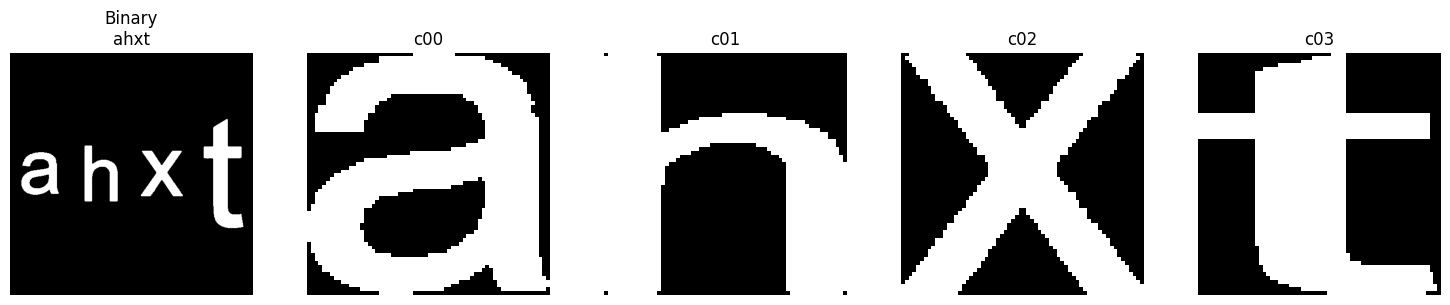

In [15]:
# Visual check for one sample image: binary + segmented 64x64 chars
demo_row = seg_df.sample(1, random_state=9).iloc[0]
demo_id = Path(demo_row["filename"]).stem

demo_binary = np.array(Image.open(binary_dir / demo_row["filename"]).convert("L"))

demo_char_files = sorted([p for p in char_64_dir.glob(f"{demo_id}_c*.png")])

n_chars = len(demo_char_files)
fig, axes = plt.subplots(1, n_chars + 1, figsize=(3 * (n_chars + 1), 3))

axes[0].imshow(demo_binary, cmap="gray")
axes[0].set_title(f"Binary\n{demo_row['label']}")
axes[0].axis("off")

for i, p in enumerate(demo_char_files, start=1):
    ch = np.array(Image.open(p).convert("L"))
    axes[i].imshow(ch, cmap="gray")
    axes[i].set_title(p.stem.split("_")[-1])
    axes[i].axis("off")

plt.tight_layout()
plt.show()

## Section 3 Notes (for report)

- Each denoised image is binarized using Otsu threshold (`gray > t` for light text on a dark background).
- Small connected components are removed as noise (`min_size=20`).
- Remaining connected components are treated as characters and sorted left-to-right.
- Number of extracted characters per image is reported in `segmentation_report.csv`.
- Every segmented character is resized to `64x64` and saved in `char_64x64` for the Mapset step.
- Threshold values are image-dependent, so they may differ between samples.

# Section 4 - Character Recognition

This section performs **non-learning recognition** by comparing segmented characters with reference templates (Mapset).

Outputs:
- Segment-level predictions with similarity metric (`section4_segment_predictions.csv`)
- Image-level predicted strings and accuracy (`section4_image_predictions.csv`)

In [16]:
# Section 4 paths
section4_dir = base_dir / "section4_recognition"
section4_dir.mkdir(parents=True, exist_ok=True)

# If user has a real mapset, place it in project root as: mapset/<char>.png
mapset_dir = Path("mapset")

segment_csv_path = section4_dir / "section4_segment_predictions.csv"
image_csv_path = section4_dir / "section4_image_predictions.csv"

print(f"Section 4 outputs: {section4_dir}")
print(f"Mapset path checked: {mapset_dir.resolve()}")

Section 4 outputs: ca2_section1_data/section4_recognition
Mapset path checked: /content/mapset


In [17]:
def normalize01(img_u8):
    x = img_u8.astype(np.float32)
    if x.max() > 1.0:
        x = x / 255.0
    return x


def make_64_binary(img_u8, threshold=127):
    """Return binary 64x64 image where foreground(text)=1, background=0."""
    pil = Image.fromarray(img_u8)
    pil = pil.resize((64, 64), Image.NEAREST)
    arr = np.array(pil, dtype=np.uint8)

    # Support both polarities: light text on dark bg, or dark text on light bg.
    if arr.mean() < 127:
        fg = (arr > threshold).astype(np.float32)
    else:
        fg = (arr < threshold).astype(np.float32)
    return fg


def cosine_similarity(a, b):
    af = a.ravel().astype(np.float32)
    bf = b.ravel().astype(np.float32)
    na = np.linalg.norm(af)
    nb = np.linalg.norm(bf)
    if na < 1e-8 or nb < 1e-8:
        return 0.0
    return float(np.dot(af, bf) / (na * nb))


def build_synthetic_mapset(chars, font_obj):
    """Fallback mapset generation if external mapset folder is missing."""
    refs = {}
    for ch in chars:
        canvas = Image.new("L", (64, 64), color=0)
        draw = ImageDraw.Draw(canvas)

        bbox = draw.textbbox((0, 0), ch, font=font_obj)
        tw = bbox[2] - bbox[0]
        th = bbox[3] - bbox[1]
        x = (64 - tw) // 2
        y = (64 - th) // 2

        # Slight bolding similar to generation
        for dx, dy in [(0, 0), (1, 0), (0, 1)]:
            draw.text((x + dx, y + dy), ch, fill=255, font=font_obj)

        refs[ch] = make_64_binary(np.array(canvas, dtype=np.uint8))
    return refs


def load_mapset(chars):
    refs = {}
    if mapset_dir.exists():
        for ch in chars:
            p1 = mapset_dir / f"{ch}.png"
            p2 = mapset_dir / f"{ch}.jpg"
            p = p1 if p1.exists() else (p2 if p2.exists() else None)
            if p is None:
                continue
            arr = np.array(Image.open(p).convert("L"), dtype=np.uint8)
            refs[ch] = make_64_binary(arr)

    # Fallback if folder missing or incomplete
    if len(refs) < len(chars):
        print("Mapset is missing/incomplete. Building synthetic mapset fallback.")
        refs = build_synthetic_mapset(chars, font)

    return refs

In [18]:
# Load reference templates (Mapset)
char_set = list(string.ascii_lowercase + string.digits)
reference_templates = load_mapset(char_set)

print(f"Loaded templates: {len(reference_templates)}")
print("Sample keys:", list(reference_templates.keys())[:10])

Mapset is missing/incomplete. Building synthetic mapset fallback.
Loaded templates: 36
Sample keys: ['a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j']


In [19]:
# Recognize all segmented characters using nearest template by cosine similarity
segment_predictions = []

for _, row in seg_df.iterrows():
    fname = row["filename"]
    img_id = Path(fname).stem

    segment_files = sorted([p for p in char_64_dir.glob(f"{img_id}_c*.png")])

    for seg_path in segment_files:
        seg_img = np.array(Image.open(seg_path).convert("L"), dtype=np.uint8)
        seg_bin = make_64_binary(seg_img)

        best_char = None
        best_score = -1.0

        for ch, ref_bin in reference_templates.items():
            s = cosine_similarity(seg_bin, ref_bin)
            if s > best_score:
                best_score = s
                best_char = ch

        segment_predictions.append({
            "segment_file": seg_path.name,
            "source_image": fname,
            "predicted_label": best_char,
            "metric": round(float(best_score), 6)
        })

segment_pred_df = pd.DataFrame(segment_predictions)
segment_pred_df.to_csv(segment_csv_path, index=False)

print(f"Saved segment predictions: {segment_csv_path}")
segment_pred_df.head(12)

Saved segment predictions: ca2_section1_data/section4_recognition/section4_segment_predictions.csv


,segment_file,source_image,predicted_label,metric
0,img_00_c00.png,img_00.png,1,0.519440
1,img_00_c01.png,img_00.png,1,0.417629
2,img_00_c02.png,img_00.png,1,0.474135
3,img_00_c03.png,img_00.png,f,0.767649
4,img_00_c04.png,img_00.png,4,0.225689
5,img_00_c05.png,img_00.png,f,0.117851
6,img_01_c00.png,img_01.png,g,0.420235
7,img_01_c01.png,img_01.png,1,0.480322
8,img_01_c02.png,img_01.png,1,0.496677
9,img_01_c03.png,img_01.png,g,0.477168


In [20]:
# Aggregate segment predictions into full 4-char strings and evaluate
image_predictions = []

for _, row in labels_df.iterrows():
    fname = row["filename"]
    true_label = row["label"]
    img_id = Path(fname).stem

    seg_rows = segment_pred_df[segment_pred_df["source_image"] == fname].copy()
    seg_rows = seg_rows.sort_values("segment_file")

    pred_chars = seg_rows["predicted_label"].tolist()
    pred_label = "".join(pred_chars)

    # Character-level accuracy for aligned prefix
    L = min(len(true_label), len(pred_label))
    char_correct = sum(1 for i in range(L) if true_label[i] == pred_label[i])
    char_acc = char_correct / len(true_label) if len(true_label) > 0 else 0.0

    exact_match = int(pred_label == true_label)

    image_predictions.append({
        "filename": fname,
        "true_label": true_label,
        "pred_label": pred_label,
        "num_segments": len(pred_chars),
        "char_accuracy": round(float(char_acc), 4),
        "exact_match": exact_match
    })

image_pred_df = pd.DataFrame(image_predictions)
image_pred_df.to_csv(image_csv_path, index=False)

overall_char_acc = image_pred_df["char_accuracy"].mean()
overall_exact_acc = image_pred_df["exact_match"].mean()

print(f"Saved image predictions: {image_csv_path}")
print(f"Overall character-level accuracy: {overall_char_acc:.2%}")
print(f"Overall exact-match accuracy: {overall_exact_acc:.2%}")

image_pred_df

Saved image predictions: ca2_section1_data/section4_recognition/section4_image_predictions.csv
Overall character-level accuracy: 0.00%
Overall exact-match accuracy: 0.00%


,filename,true_label,pred_label,num_segments,char_accuracy,exact_match
0,img_00.png,xaji,111f4f,6,0.0,0
1,img_01.png,0y6d,g11g,4,0.0,0
2,img_02.png,pbhs,ggg1,4,0.0,0
3,img_03.png,ahxt,1g11,4,0.0,0
4,img_04.png,hv3a,g1g1,4,0.0,0
5,img_05.png,3zmf,ggg1,4,0.0,0
6,img_06.png,8mdd,1ggg,4,0.0,0
7,img_07.png,4v30,g1gg,4,0.0,0
8,img_08.png,t9nt,1111,4,0.0,0
9,img_09.png,3w5u,g1g1,4,0.0,0


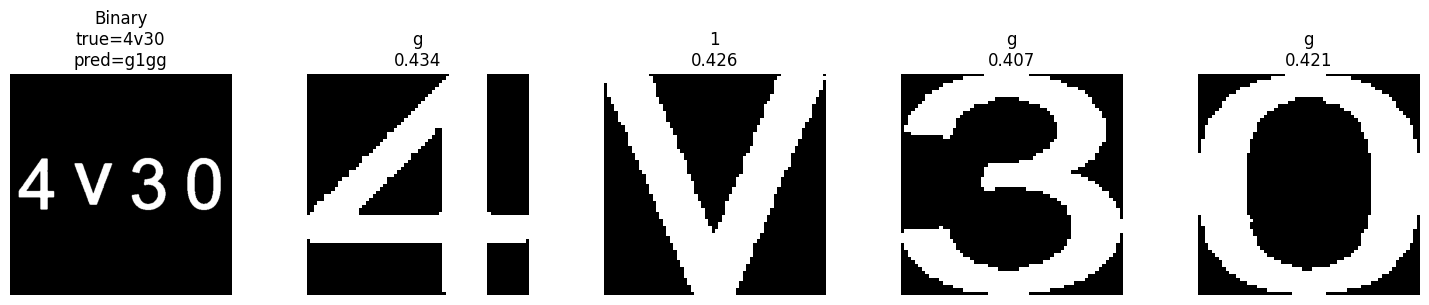

In [21]:
# Visual demo: one image with its segmented predictions
demo = image_pred_df.sample(1, random_state=21).iloc[0]
demo_id = Path(demo["filename"]).stem
demo_seg = segment_pred_df[segment_pred_df["source_image"] == demo["filename"]].sort_values("segment_file")

demo_bin = np.array(Image.open(binary_dir / demo["filename"]).convert("L"), dtype=np.uint8)
seg_files = [char_64_dir / s for s in demo_seg["segment_file"].tolist()]

n = len(seg_files)
fig, axes = plt.subplots(1, n + 1, figsize=(3 * (n + 1), 3))
axes[0].imshow(demo_bin, cmap="gray")
axes[0].set_title(f"Binary\ntrue={demo['true_label']}\npred={demo['pred_label']}")
axes[0].axis("off")

for i, (seg_path, (_, r)) in enumerate(zip(seg_files, demo_seg.iterrows()), start=1):
    arr = np.array(Image.open(seg_path).convert("L"), dtype=np.uint8)
    axes[i].imshow(arr, cmap="gray")
    axes[i].set_title(f"{r['predicted_label']}\n{r['metric']:.3f}")
    axes[i].axis("off")

plt.tight_layout()
plt.show()

## Section 4 Notes (for report)

- Recognition method is **non-learning**: nearest-template matching using cosine similarity.
- For each segmented file, the best matching template label and metric are stored in CSV.
- Final string for each image is formed by concatenating segment predictions left-to-right.
- Two evaluation metrics are reported over all 20 images:
  - character-level accuracy
  - exact-match accuracy
- Acceptance target is at least **90%** final accuracy.
- **Confusable pairs** (`l` vs `1`, `o` vs `0`, etc.): if cosine similarity is ambiguous, consider extra cues from the project hints — **edge structure**, **aspect ratio** of the character bbox, and **resizing Mapset** templates to match segmented glyph scale before similarity.

# Section 4 - Character Recognition

In this section, we recognize segmented characters using a **non-learning similarity method** with reference templates from `Mapset`.

Pipeline:
1. Load template images from `Mapset`.
2. Compare each segmented `64x64` character to all templates.
3. Select best label by maximum similarity metric.
4. Save per-segment predictions to CSV and evaluate final accuracy.

In [23]:
import re

# Set your Mapset directory (update if needed)
mapset_dir = Path("Mapset")

if not mapset_dir.exists():
    raise FileNotFoundError(
        "Mapset folder not found. Put your reference character images in a folder named 'Mapset' "
        "next to this notebook or update mapset_dir path in this cell."
    )

template_files = sorted([p for p in mapset_dir.glob("*.*") if p.suffix.lower() in {".png", ".jpg", ".jpeg", ".bmp"}])
if len(template_files) == 0:
    raise FileNotFoundError("No template image files found in Mapset folder.")

print(f"Found {len(template_files)} template files in: {mapset_dir}")

Found 36 template files in: Mapset


In [24]:
def extract_label_from_template_name(stem):
    # Expected: filenames containing one alphanumeric label (e.g., a.png, a_1.png, template_a.png)
    m = re.search(r"[a-z0-9]", stem.lower())
    if m is None:
        raise ValueError(f"Could not infer label from template filename: {stem}")
    return m.group(0)


def to_binary64(img_path):
    img = np.array(Image.open(img_path).convert("L"), dtype=np.float32)
    t = otsu_threshold(img)
    if img.mean() < 127:
        b = (img > t).astype(np.uint8)
    else:
        b = (img < t).astype(np.uint8)
    return b


def cosine_similarity(a, b):
    a = a.astype(np.float32).ravel()
    b = b.astype(np.float32).ravel()
    na = np.linalg.norm(a)
    nb = np.linalg.norm(b)
    if na == 0 or nb == 0:
        return 0.0
    return float(np.dot(a, b) / (na * nb))

# Build template bank (label -> list of template arrays)
template_bank = {}
for tp in template_files:
    label_key = extract_label_from_template_name(tp.stem)
    b = to_binary64(tp)
    # Enforce 64x64 for fair comparison
    b64 = np.array(Image.fromarray((b * 255).astype(np.uint8)).resize((64, 64), Image.NEAREST)) > 0
    b64 = b64.astype(np.uint8)
    template_bank.setdefault(label_key, []).append(b64)

print("Template labels:", sorted(template_bank.keys()))

Template labels: ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9', 'a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j', 'k', 'l', 'm', 'n', 'o', 'p', 'q', 'r', 's', 't', 'u', 'v', 'w', 'x', 'y', 'z']


In [25]:
# Recognize all segmented characters and save per-segment metrics
char_files = sorted(char_64_dir.glob("*.png"))
if len(char_files) == 0:
    raise FileNotFoundError("No segmented 64x64 character images found. Run Section 3 first.")

pred_records = []
for cf in char_files:
    q = np.array(Image.open(cf).convert("L"), dtype=np.float32)
    q_bin = (q > 127).astype(np.uint8)

    best_label = None
    best_score = -1.0

    for lbl, tmpl_list in template_bank.items():
        # Use the best match among templates of same label
        score = max(cosine_similarity(q_bin, t) for t in tmpl_list)
        if score > best_score:
            best_score = score
            best_label = lbl

    # filename format from section 3: img_XX_cYY.png
    m = re.match(r"(img_\d+)_c(\d+)\.png", cf.name)
    image_id = m.group(1) if m else cf.stem
    char_index = int(m.group(2)) if m else -1

    pred_records.append({
        "segment_file": cf.name,
        "image_id": image_id,
        "char_index": char_index,
        "predicted_label": best_label,
        "metric": round(best_score, 6)
    })

pred_df = pd.DataFrame(pred_records).sort_values(["image_id", "char_index"]).reset_index(drop=True)
pred_csv_path = seg_base_dir / "section4_segment_predictions.csv"
pred_df.to_csv(pred_csv_path, index=False)

print(f"Saved per-segment predictions to: {pred_csv_path}")
pred_df.head(12)

Saved per-segment predictions to: ca2_section1_data/section3_segmentation/section4_segment_predictions.csv


,segment_file,image_id,char_index,predicted_label,metric
0,img_00_c00.png,img_00,0,y,0.591703
1,img_00_c01.png,img_00,1,7,0.476497
2,img_00_c02.png,img_00,2,y,0.478913
3,img_00_c03.png,img_00,3,f,0.707143
4,img_00_c04.png,img_00,4,f,0.701805
5,img_00_c05.png,img_00,5,f,0.701204
6,img_01_c00.png,img_01,0,7,0.354907
7,img_01_c01.png,img_01,1,y,0.826649
8,img_01_c02.png,img_01,2,f,0.442328
9,img_01_c03.png,img_01,3,f,0.395922


In [26]:
# Build image-level predicted strings and evaluate against ground-truth labels
pred_string_df = (
    pred_df.sort_values(["image_id", "char_index"])
           .groupby("image_id")["predicted_label"]
           .apply(lambda s: "".join(s.tolist()))
           .reset_index(name="predicted_string")
)

truth_df = labels_df.copy()
truth_df["image_id"] = truth_df["filename"].str.replace(".png", "", regex=False)
truth_df = truth_df[["image_id", "label"]]

eval_df = truth_df.merge(pred_string_df, on="image_id", how="left")
eval_df["predicted_string"] = eval_df["predicted_string"].fillna("")

# Strict full-string match accuracy (target >= 90%)
eval_df["correct"] = (eval_df["predicted_string"] == eval_df["label"]).astype(int)
string_accuracy = eval_df["correct"].mean()

# Optional character-level accuracy for analysis
char_total = 0
char_correct = 0
for _, r in eval_df.iterrows():
    gt = r["label"]
    pr = r["predicted_string"]
    n = min(len(gt), len(pr))
    char_correct += sum(gt[i] == pr[i] for i in range(n))
    char_total += len(gt)
char_accuracy = char_correct / char_total if char_total > 0 else 0.0

eval_csv_path = seg_base_dir / "section4_image_level_evaluation.csv"
eval_df.to_csv(eval_csv_path, index=False)

print(f"Saved image-level evaluation to: {eval_csv_path}")
print(f"String-level accuracy: {string_accuracy*100:.2f}%")
print(f"Character-level accuracy: {char_accuracy*100:.2f}%")

eval_df

Saved image-level evaluation to: ca2_section1_data/section3_segmentation/section4_image_level_evaluation.csv
String-level accuracy: 0.00%
Character-level accuracy: 5.00%


,image_id,label,predicted_string,correct
0,img_00,xaji,y7yfff,0
1,img_01,0y6d,7yff,0
2,img_02,pbhs,7fyy,0
3,img_03,ahxt,7yyf,0
4,img_04,hv3a,yy77,0
5,img_05,3zmf,777f,0
6,img_06,8mdd,y7ff,0
7,img_07,4v30,fy77,0
8,img_08,t9nt,fy7f,0
9,img_09,3w5u,7ffy,0


## Section 4 Notes (for report)

- Recognition is done by **template matching** (non-learning method).
- Similarity metric is **cosine similarity** between binary `64x64` vectors.
- For each segmented character, we predict the label of the template with maximum similarity.
- Per-segment outputs are saved in `section4_segment_predictions.csv` with metric values.
- Final performance is reported in `section4_image_level_evaluation.csv` using full-string match accuracy.
- If accuracy is below target, improve Section 2/3 (cleaner denoising and segmentation) and use better Mapset templates.
- **Ambiguous classes:** follow course hints — compare **boundary/edge statistics**, **width-to-height ratio**, and ensure Mapset references are **scale-matched** (resize templates) to segmented `64x64` glyphs.